# Bootstrap: Taxi + Q-table

# Bootstrap: Taxi + Q-table

This notebook is the warm-up for the Lunar Lander project. Before using deep neural networks (DQN/PPO), we prove we understand the fundamentals of RL by solving a smaller problem: **Taxi-v4** using a tabular Q-learning agent.

**The environment:** A 5x5 grid. The taxi must pick up a passenger at one of 4 locations and drop them off at another. 
**State space:** 500 discrete states (25 taxi positions × 5 passenger locations × 4 destinations).
**Action space:** 6 discrete actions (South, North, East, West, Pickup, Dropoff).
**Rewards:** -1 per step, +20 for a successful dropoff, -10 for illegal pickup/dropoff.

## 1. Environment

In [6]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt

env = gym.make("Taxi-v4")

# Q-table: 500 states x 6 actions, initialized to zeros
state_dim = env.observation_space.n
action_dim = env.action_space.n
q_table = np.zeros((state_dim, action_dim))

print(f"State space: {state_dim}, Action space: {action_dim}")

State space: 500, Action space: 6


## 2. RL loop + random baseline
Before training, let's see how a random agent performs. We run 100 episodes where the taxi just presses random buttons.

In [7]:
def run_random_baseline(env, n_episodes=100):
    rewards = []
    for _ in range(n_episodes):
        state, _ = env.reset()
        total_reward = 0
        done = False
        while not done:
            action = env.action_space.sample()
            next_state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            done = terminated or truncated
        rewards.append(total_reward)
    return np.mean(rewards), np.std(rewards)

mean_r, std_r = run_random_baseline(env)
print(f"Random baseline: mean={mean_r:.1f}, std={std_r:.1f}")

Random baseline: mean=-782.2, std=60.1


## 3. Q-table + update rule (terminated vs truncated)
The Q-learning update rule is:
\[
Q(s,a) \leftarrow Q(s,a) + \alpha \left[ r + \gamma \max_{a'} Q(s',a') - Q(s,a) \right]
\]

**Important detail (terminated vs truncated):**
If an episode *terminated* (the taxi dropped off the passenger), there is no future. The target is just \(r\).
If an episode was *truncated* (hit the 200-step time limit), the state \(s'\) still has value. We must bootstrap: use \(r + \gamma \max Q(s',a')\).

In [8]:
def update_q_table(q_table, state, action, reward, next_state, terminated, alpha=0.1, gamma=0.99):
    # The current estimate
    current_q = q_table[state, action]
    
    # The target: no future if truly terminated (e.g., crash or success)
    if terminated:
        target = reward
    else:
        # If truncated or just ongoing, bootstrap the future
        target = reward + gamma * np.max(q_table[next_state])
        
    # Update
    q_table[state, action] = current_q + alpha * (target - current_q)

## 4. Epsilon-greedy + training
We need exploration. With probability \(\epsilon\), we take a random action. With probability \(1-\epsilon\), we trust the Q-table. We decay \(\epsilon\) from 1.0 to 0.01 over the first 10,000 episodes.

In [9]:
def train_q_learning(env, q_table, n_episodes=20000, alpha=0.1, gamma=0.99, epsilon_start=1.0, epsilon_end=0.01, epsilon_decay=0.999):
    rewards = []
    epsilons = []
    
    for episode in range(n_episodes):
        state, _ = env.reset()
        total_reward = 0
        done = False
        
        # Decay epsilon
        epsilon = max(epsilon_end, epsilon_start * (epsilon_decay ** episode))
        
        while not done:
            # Epsilon-greedy action selection
            if np.random.rand() < epsilon:
                action = env.action_space.sample() # Explore
            else:
                action = np.argmax(q_table[state]) # Exploit
                
            next_state, reward, terminated, truncated, _ = env.step(action)
            done = terminated or truncated
            
            # Update the table
            update_q_table(q_table, state, action, reward, next_state, terminated, alpha, gamma)
            
            state = next_state
            total_reward += reward
            
        rewards.append(total_reward)
        epsilons.append(epsilon)
        
    return rewards, epsilons

print("Training... (this may take a minute)")
rewards, epsilons = train_q_learning(env, q_table, n_episodes=20000)
print("Done.")

Training... (this may take a minute)
Done.


## 5. Evaluation (no exploration)
Now we evaluate the trained Q-table with \(\epsilon = 0\) (pure exploitation) over 100 episodes to see if it can reliably solve the task.

In [13]:
def evaluate_q_learning(env, q_table, n_episodes=100):
    rewards = []
    for _ in range(n_episodes):
        state, _ = env.reset()
        total_reward = 0
        done = False
        while not done:
            action = np.argmax(q_table[state])
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            done = terminated or truncated
        rewards.append(total_reward)
    return np.mean(rewards), np.std(rewards)

eval_mean, eval_std = evaluate_q_learning(env, q_table)
print(f"Trained agent evaluation: mean={eval_mean:.1f}, std={eval_std:.1f}")
print("A perfect score in Taxi-v4 is +8 (15 steps: -15 + 20 + 3).")

Trained agent evaluation: mean=7.6, std=2.4
A perfect score in Taxi-v4 is +8 (15 steps: -15 + 20 + 3).


## 6. Experiments (write prediction first)

**Prediction:** If I set `gamma=0.0` (no discounting of the future), the agent will become extremely greedy and short-sighted. It will likely learn to just pick up and drop off repeatedly or take random steps to get the -1 penalty, failing to understand that it needs to travel far away for the +20 dropoff. The evaluation score will drop massively.

Let's test this by re-training a new Q-table with `gamma=0.0`.

In [11]:
q_table_gamma0 = np.zeros((state_dim, action_dim))
# Train with gamma = 0.0
train_q_learning(env, q_table_gamma0, n_episodes=20000, gamma=0.0)

eval_mean_g0, _ = evaluate_q_learning(env, q_table_gamma0)
print(f"Evaluation with gamma=0.0: mean={eval_mean_g0:.1f}")
print("As predicted, the agent fails to learn the long-term value of the +20 reward.")

Evaluation with gamma=0.0: mean=-200.0
As predicted, the agent fails to learn the long-term value of the +20 reward.


## 7. Beyond the table

**Why can't we use this for Lunar Lander?**
1. **Continuous states:** Taxi has 500 states. Lunar Lander has 8 continuous float values (position, velocity, angle, etc.). A Q-table would require a row for every possible float combination (infinite).
2. **Continuous actions:** Lunar Lander has 4 discrete actions, but if it had continuous thrusters, a Q-table couldn't map them.
3. **Generalization:** The tabular agent memorizes exactly 500 states. If we change the screen size or gravity slightly, it fails completely. Neural networks (DQN) can generalize across similar states.

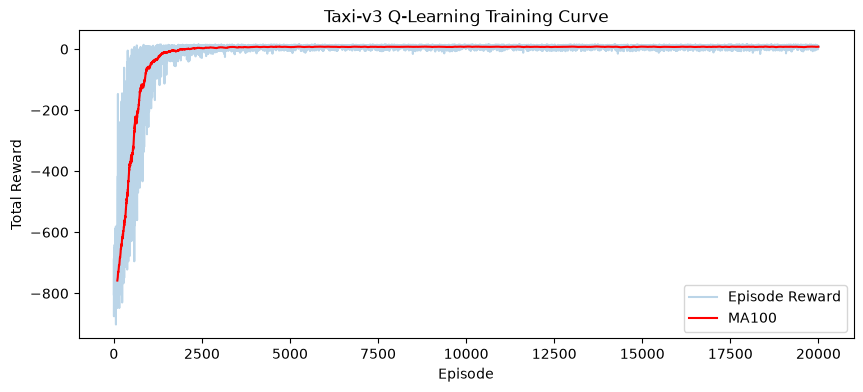

In [12]:
# Quick plot of the learning curve
plt.figure(figsize=(10, 4))
plt.plot(rewards, alpha=0.3, label="Episode Reward")
window = 100
ma = np.convolve(rewards, np.ones(window)/window, mode='valid')
plt.plot(range(window-1, len(rewards)), ma, color='red', label=f"MA{window}")
plt.xlabel("Episode")
plt.ylabel("Total Reward")
plt.title("Taxi-v3 Q-Learning Training Curve")
plt.legend()
plt.show()